# Plots

In [1]:
from ochem.utils import plot_ramp, rate_from_ramp, area_to_conc, a_by_b, moving_avg
import pandas as pd

In [28]:
def load_csv(filename: str, is_output: bool = False):
    return pd.read_csv(f"../../{'output' if is_output else 'input' }/C-107/{filename}")

In [29]:
expdata = load_csv("experiment.csv")

def get_data(name: str):
    return expdata[expdata['product_name'] == name]
# all_experiment_data

## Rate Ramps

In [72]:
def rate_from_ramp(data, y_labels, export = None):
    df = data.copy()
    df['delta_time'] = df['time'] - df['time'].shift(1)
    if 'temp' in df.columns:
        df['avg_temp'] = (df['temp'] - df['temp'].shift(1)) / 2
    for label in y_labels:
        df[f"rate_{label}"] = (df[label] - df[label].shift(1)) / df['delta_time']
    if export is not None:
        df.to_csv()
    return df

In [73]:
def moving_avg(data, y_labels, window, export = False):
    cols = ['time', 'temp', *y_labels]
    df = data.copy()
    for col in cols:
        df[col] = sum([df[col].shift(i) for i in range(window)]) / window
    if export:
        df.to_csv(export)
    return df.iloc[1:]

In [85]:
def process_data(data, rxns, y_labels):
    products = {product_name: product_data for product_name, product_data in data.groupby('product_name')}
    for name, data in products.items():
        rate = rate_from_ramp(data, rxns)
        smooth = moving_avg(data, rxns, 2)
        plot_ramp(smooth, rxns = rxns, y_labels= y_labels, y_name=f"{name} (is)", title=name)

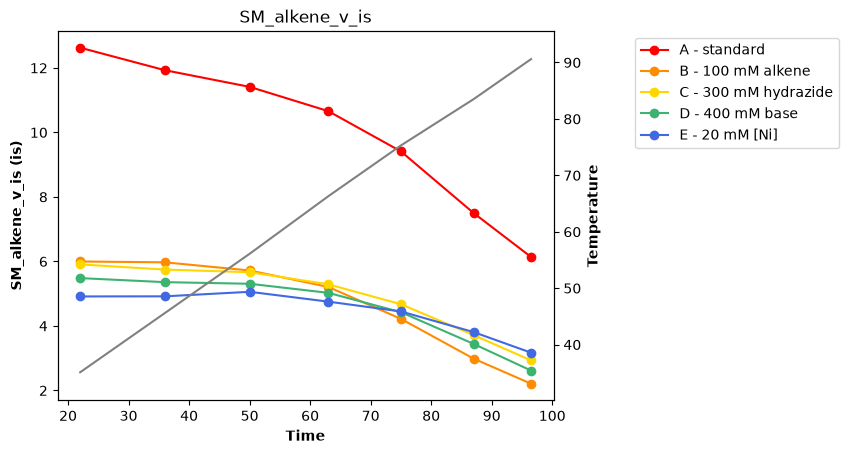

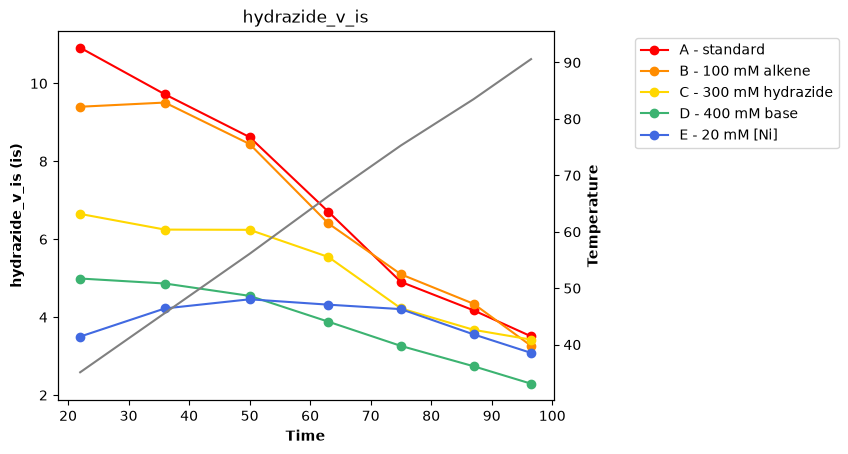

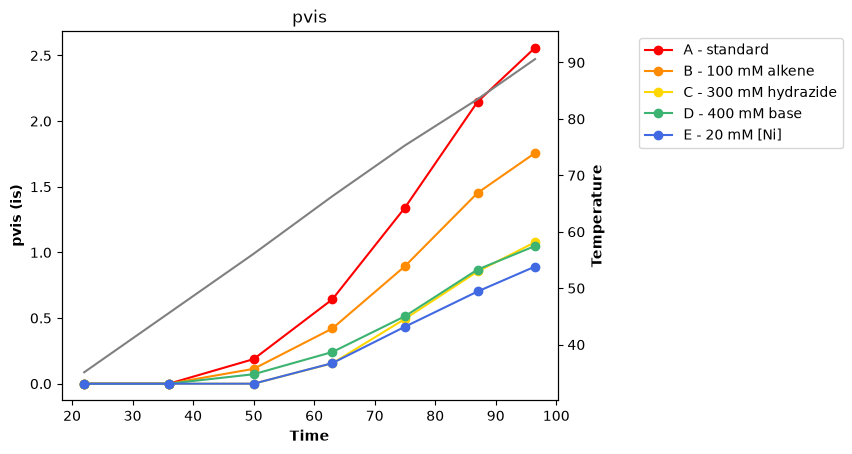

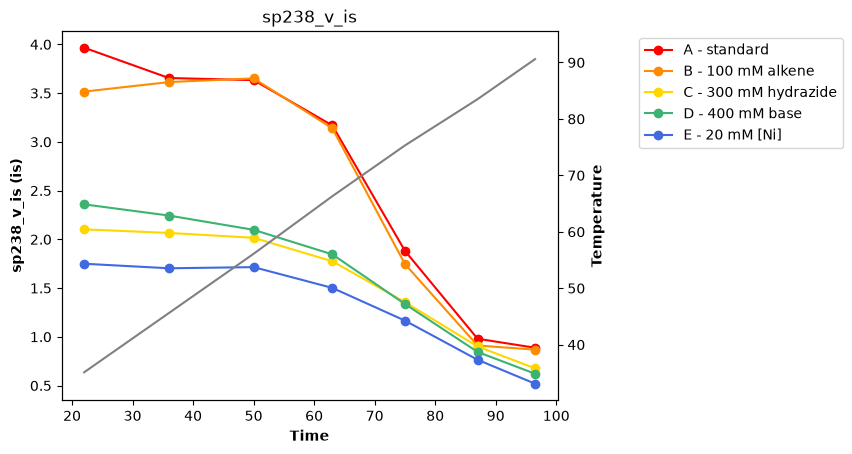

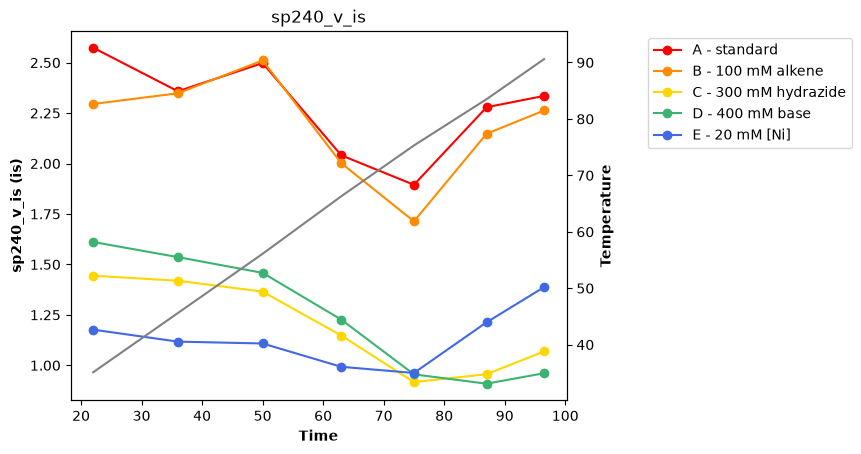

In [87]:
y_labels = ["A - standard",
            "B - 100 mM alkene",
            "C - 300 mM hydrazide",
            "D - 400 mM base",
            "E - 20 mM [Ni]"]
rxns = ["A","B","C","D","E"]

process_data(expdata, rxns, y_labels)

In [67]:
pvis_smooth

,product_name,time,temp,A,B,C,D,E
17,pvis,22.0,35.1,0.000000,0.000000,0.000000,0.000000,0.000000
18,pvis,36.0,45.6,0.000000,0.000000,0.000000,0.000000,0.000000
19,pvis,50.0,56.1,0.187154,0.113158,0.000000,0.072167,0.000000
20,pvis,63.0,66.3,0.642353,0.420460,0.155027,0.241075,0.156395
21,pvis,75.0,75.3,1.340913,0.894958,0.493329,0.513740,0.433984
22,pvis,87.0,83.5,2.147342,1.453159,0.854798,0.869414,0.702344
23,pvis,96.5,90.6,2.559272,1.757387,1.077911,1.048841,0.892189


### PVIS

### Hydrazide

### Alkene

### SP238

### SP240